In [19]:
import numpy as np 
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt 
import warnings 

warnings.filterwarnings('ignore')

In [20]:
df = pd.read_csv('Housing.csv')

In [21]:
df

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,1767150,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,1750000,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,1750000,2910,3,1,1,no,no,no,no,no,0,no,furnished


EDA

In [22]:
df.shape

(545, 13)

In [23]:
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [24]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 69.2 KB


In [25]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [26]:
df.isnull().sum()

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

In [27]:
df.columns

Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus'],
      dtype='str')

In [28]:
df = df[['area', 'bedrooms', 'bathrooms','stories', 'parking', 'price']]
df

,area,bedrooms,bathrooms,stories,parking,price
0,7420,4,2,3,2,13300000
1,8960,4,4,4,3,12250000
2,9960,3,2,2,2,12250000
3,7500,4,2,2,3,12215000
4,7420,4,1,2,2,11410000
...,...,...,...,...,...,...
540,3000,2,1,1,2,1820000
541,2400,3,1,1,0,1767150
542,3620,2,1,1,0,1750000
543,2910,3,1,1,0,1750000


In [29]:
df.duplicated().sum()

np.int64(1)

In [30]:
df.corr()

,area,bedrooms,bathrooms,stories,parking,price
area,1.000000,0.151858,0.193820,0.083996,0.352980,0.535997
bedrooms,0.151858,1.000000,0.373930,0.408564,0.139270,0.366494
bathrooms,0.193820,0.373930,1.000000,0.326165,0.177496,0.517545
stories,0.083996,0.408564,0.326165,1.000000,0.045547,0.420712
parking,0.352980,0.139270,0.177496,0.045547,1.000000,0.384394
price,0.535997,0.366494,0.517545,0.420712,0.384394,1.000000


In [31]:
price_corr = df.corr()['price'].sort_values(ascending=False)
price_corr

price        1.000000
area         0.535997
bathrooms    0.517545
stories      0.420712
parking      0.384394
bedrooms     0.366494
Name: price, dtype: float64

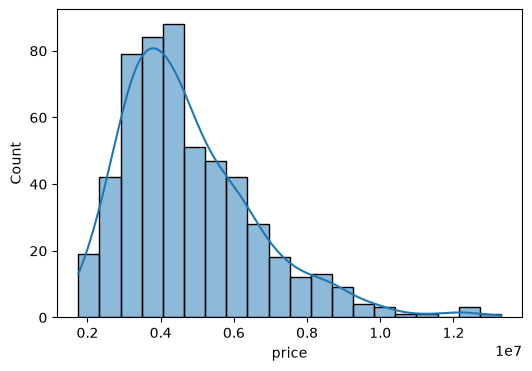

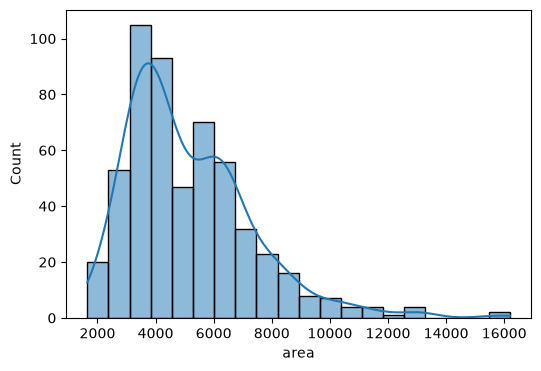

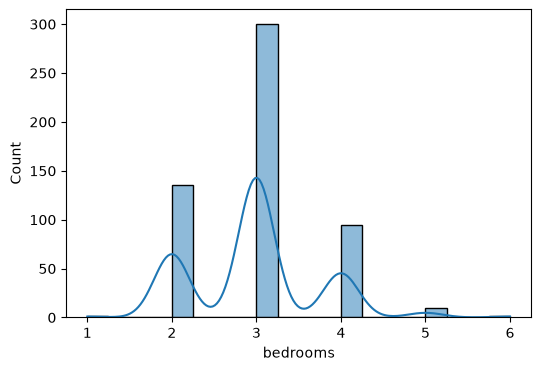

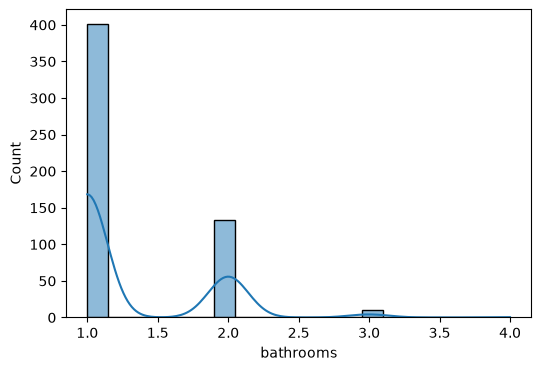

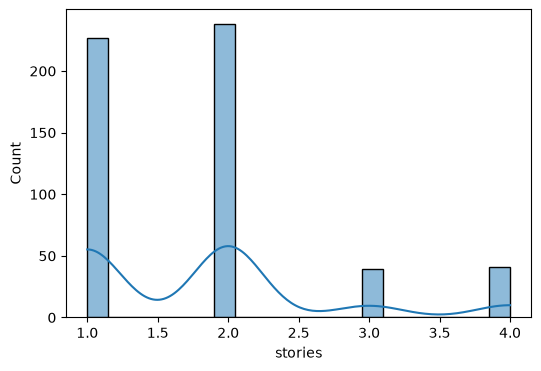

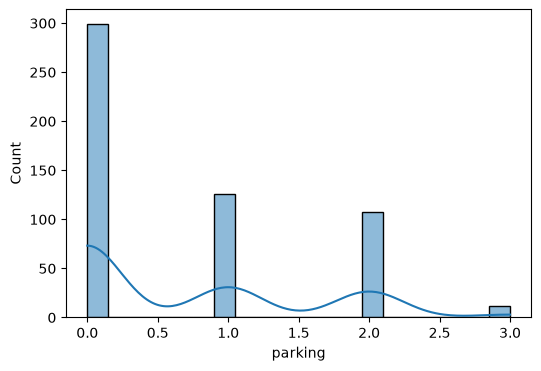

In [32]:
numeric_columns = ['price', 'area', 'bedrooms','bathrooms','stories','parking']
for col in numeric_columns:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col],kde = True,bins = 20)

<Axes: xlabel='bedrooms', ylabel='count'>

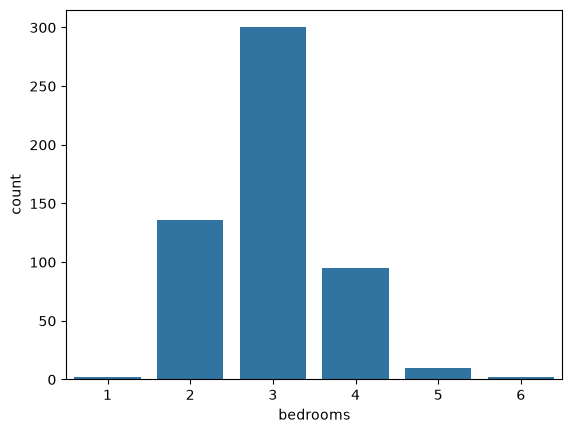

In [33]:
sns.countplot(x = df['bedrooms'])

<Axes: xlabel='parking', ylabel='count'>

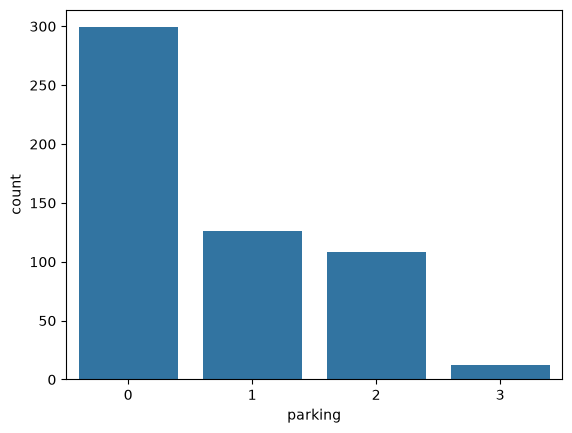

In [34]:
sns.countplot(x = df['parking'])

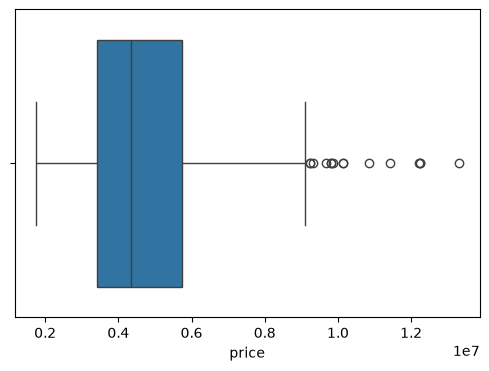

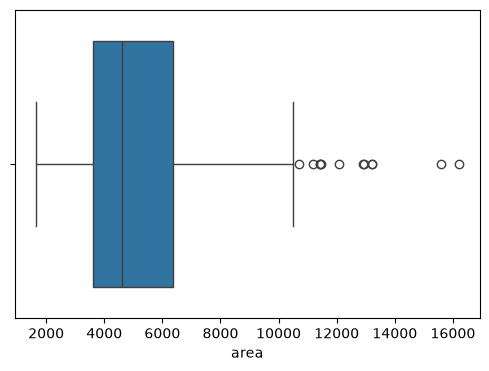

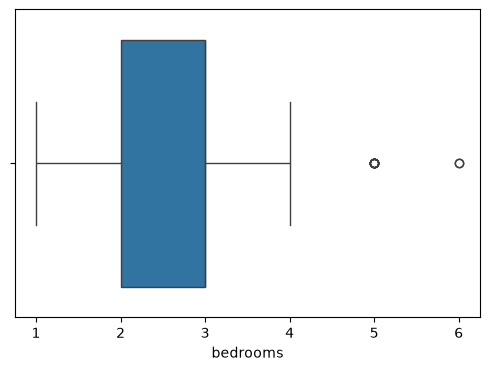

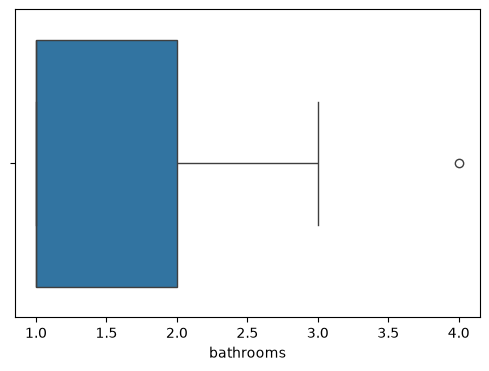

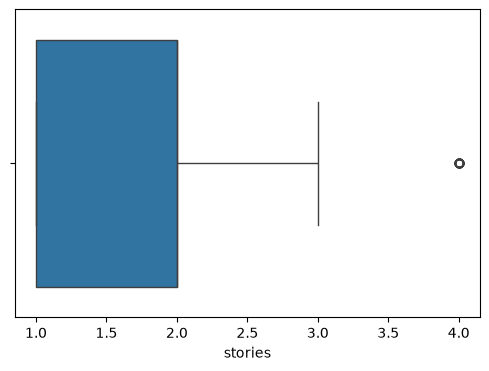

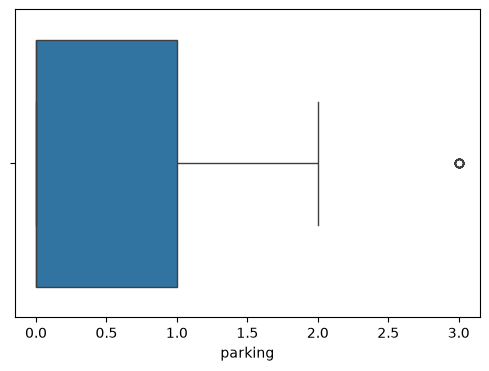

In [36]:
for col in numeric_columns:
    plt.figure(figsize= (6,4))
    sns.boxplot(x = df[col])

<Axes: >

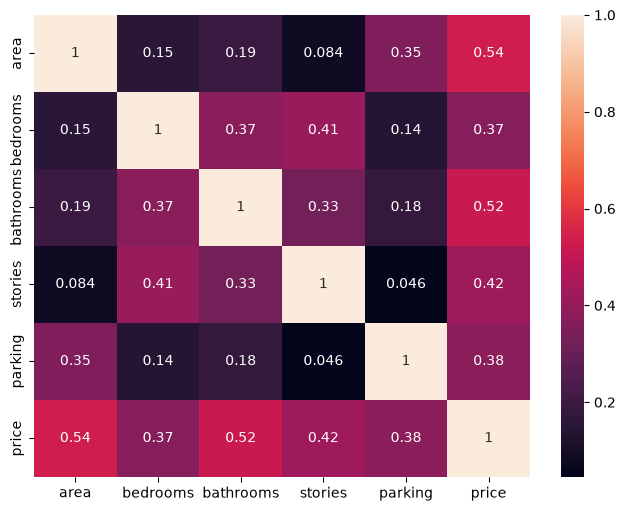

In [37]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True),annot=True)

Data Cleaning and preprocessing


In [38]:

df_cleaned = df.copy()

In [39]:
df_cleaned.head()

,area,bedrooms,bathrooms,stories,parking,price
0,7420,4,2,3,2,13300000
1,8960,4,4,4,3,12250000
2,9960,3,2,2,2,12250000
3,7500,4,2,2,3,12215000
4,7420,4,1,2,2,11410000


In [40]:
df_cleaned.shape

(545, 6)

In [41]:
df_cleaned.drop_duplicates(inplace = True)

In [42]:
df_cleaned.shape

(544, 6)

In [43]:

df_cleaned.isnull().sum()

area         0
bedrooms     0
bathrooms    0
stories      0
parking      0
price        0
dtype: int64

In [44]:

df_cleaned.dtypes

area         int64
bedrooms     int64
bathrooms    int64
stories      int64
parking      int64
price        int64
dtype: object

In [47]:
from sklearn.model_selection import train_test_split

In [48]:
x = df_cleaned.drop('price',axis = 1)
y = df_cleaned['price']

In [49]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size = 0.2, random_state = 42)

In [50]:
print(x_train.shape)
print(x_test.shape)

(435, 5)
(109, 5)


In [53]:
from sklearn.linear_model import LinearRegression

In [56]:
model = LinearRegression()

In [57]:
model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[ 311.58, 207489.74,1181551.55, 474539.96, 374904.04]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['area','bedrooms','bathrooms','stories','parking']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-8.815e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


In [59]:
y_pred = model.predict(x_test)
y_pred

array([3864524.08835596, 4760924.13832832, 5406575.88286229,
       3412737.03946747, 3097101.48931828, 6346295.37958658,
       4759693.37018281, 6321369.19757894, 4586290.22145574,
       6205898.70008899, 9607765.4551541 , 3333284.83431811,
       4712769.87321387, 5178149.42111352, 3901913.36136742,
       3385019.61343718, 3424257.62816857, 4909319.2737405 ,
       4549225.47717258, 3367336.29074602, 5092812.2313999 ,
       3337958.49344455, 4726035.25399505, 5883125.36502069,
       6959566.55538082, 7699620.87882753, 4025277.2403746 ,
       4975075.03023886, 7527579.69835738, 4145941.84383785,
       5381312.0662077 , 5608763.47702742, 4716210.17469313,
       5217711.96457321, 3665114.63229483, 5588647.26689121,
       4161533.81351127, 4922358.73999201, 3528345.15998111,
       3208666.87573312, 6267202.84129352, 4209897.10266293,
       4693063.92289357, 3382915.15450079, 3353861.88592763,
       5731358.73964109, 5727336.72747293, 6022392.63651095,
       3104600.06585122,

In [60]:
Comparison = pd.DataFrame({'Actual':y_test,'Predicted':y_pred})
Comparison

,Actual,Predicted
458,3115000,3.864524e+06
257,4480000,4.760924e+06
357,3773000,5.406576e+06
533,2100000,3.412737e+06
543,1750000,3.097101e+06
...,...,...
507,2590000,3.104600e+06
278,4277000,4.474122e+06
46,7525000,7.039951e+06
93,6300000,6.740032e+06


In [61]:
mae = np.mean(np.abs(y_test - y_pred))
mse = np.mean((y_test - y_pred)**2)
rmse = np.sqrt(mse) 
r2 = model.score(x_test,y_test)
print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R-squared:", r2)

Mean Absolute Error: 1141982.0301240026
Mean Squared Error: 2295578854720.5703
Root Mean Squared Error: 1515116.779235373
R-squared: 0.533646979764798


In [63]:
new_house = pd.DataFrame({'area':[2500],'bedrooms':[4],'bathrooms':[3],'stories':[2],'parking':[2]})
new_house_pred = model.predict(new_house)
print("Predicted price for the new house:", new_house_pred[0])

Predicted price for the new house: 6764295.7016775785
